
# Customer Segmentation Using K-Means Clustering

## Project Overview
In this project, I analyze customer data to understand their income, spending habits, purchases, and shopping behaviour. I use K-Means Clustering, an unsupervised machine learning algorithm, to group customers with similar characteristics.

## Objective
- Understand customer data using Exploratory Data Analysis (EDA).
- Identify patterns in customer income and spending.
- Group similar customers using K-Means Clustering.
- Visualize the customer groups using PCA.
- Compare the average income, spending, and purchases of each group.

## Tools and Technologies
- **Programming Language:** Python
- **Libraries:** NumPy, Pandas, Matplotlib, Seaborn
- **Machine Learning:** Scikit-learn
- **Environment:** Kaggle Notebook

## Dataset Information
The dataset contains customer details, demographics, purchase history, spending across product categories, website visits, and marketing campaign responses.

### Important Columns

| Column | Description |
|---|---|
| `ID` | Unique customer identifier |
| `Year_Birth` | Customer's birth year |
| `Education` | Customer's education level |
| `Marital_Status` | Customer's marital status |
| `Income` | Customer's yearly income |
| `Recency` | Days since the last purchase |
| `MntWines`, `MntFruits`, etc. | Spending on different product categories |
| `NumWebPurchases` | Purchases made through the website |
| `NumCatalogPurchases` | Purchases made through the catalog |
| `NumStorePurchases` | Purchases made in stores |
| `NumWebVisitsMonth` | Website visits per month |
| `AcceptedCmp1` to `AcceptedCmp5` | Responses to previous marketing campaigns |
| `Response` | Response to the latest campaign |
| `Complain` | Whether the customer complained |



## Importing Required Libraries

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading

In [2]:
path='/kaggle/input/datasets/vishakhdapat/customer-segmentation-clustering/customer_segmentation.csv'
df=pd.read_csv(path)

## Understanding Dataset

In [3]:
df.shape

(2240, 29)

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [9]:
df=df.dropna(subset=['Income'])

In [10]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

In [11]:
df['Dt_Customer']=pd.to_datetime(df['Dt_Customer'],dayfirst=True)

In [12]:
df['Total_Spendings']=df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntSweetProducts']+df['MntGoldProds']
df['Num_of_Cmp_Accepted']=df['AcceptedCmp3']+df['AcceptedCmp4']+df['AcceptedCmp5']+df['AcceptedCmp1']+df['AcceptedCmp2']

In [13]:
df['Total_Purchases']=df['NumWebPurchases']+df['NumCatalogPurchases']+df['NumStorePurchases']

In [14]:
df['Age']=2013-df['Year_Birth']

In [15]:
df['Total_Children']=df['Kidhome']+df['Teenhome']

In [16]:
reference_date=df['Dt_Customer'].max()

In [17]:
df['Customer_Since']=(reference_date-df['Dt_Customer']).dt.days

In [18]:
df=df.drop(columns=['Dt_Customer','MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds','AcceptedCmp2','AcceptedCmp1','AcceptedCmp5','AcceptedCmp4','AcceptedCmp3','NumWebPurchases','NumCatalogPurchases','NumStorePurchases','Year_Birth','Kidhome','Teenhome'])

In [19]:
df.head()

,ID,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebVisitsMonth,Complain,Z_CostContact,Z_Revenue,Response,Total_Spendings,Num_of_Cmp_Accepted,Total_Purchases,Age,Total_Children,Customer_Since
0,5524,Graduation,Single,58138.0,58,3,7,0,3,11,1,1617,0,22,56,0,663
1,2174,Graduation,Single,46344.0,38,2,5,0,3,11,0,27,0,4,59,2,113
2,4141,Graduation,Together,71613.0,26,1,4,0,3,11,0,776,0,20,48,0,312
3,6182,Graduation,Together,26646.0,26,2,6,0,3,11,0,53,0,6,29,1,139
4,5324,PhD,Married,58293.0,94,5,5,0,3,11,0,422,0,14,32,1,161


In [20]:
df['Z_CostContact'].value_counts()

Z_CostContact
3    2216
Name: count, dtype: int64

In [21]:
df['Z_Revenue'].value_counts()

Z_Revenue
11    2216
Name: count, dtype: int64

In [22]:
df=df.drop(columns=['Z_Revenue','Z_CostContact'])

In [23]:
df.columns

Index(['ID', 'Education', 'Marital_Status', 'Income', 'Recency',
       'NumDealsPurchases', 'NumWebVisitsMonth', 'Complain', 'Response',
       'Total_Spendings', 'Num_of_Cmp_Accepted', 'Total_Purchases', 'Age',
       'Total_Children', 'Customer_Since'],
      dtype='object')

## Exploratory Data Analysis

In [24]:
num_cols=df.select_dtypes(include=('number')).columns.tolist()
cat_cols=df.select_dtypes(include=('object')).columns.tolist()

In [25]:
cat_cols.append('Complain')
cat_cols.append('Response')

In [26]:
num_cols.remove('Complain')
num_cols.remove('Response')

In [27]:
print("Numerical Columns:",num_cols)
num_cols.remove('ID')
print("Categorical Columns:",cat_cols)

Numerical Columns: ['ID', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Total_Spendings', 'Num_of_Cmp_Accepted', 'Total_Purchases', 'Age', 'Total_Children', 'Customer_Since']
Categorical Columns: ['Education', 'Marital_Status', 'Complain', 'Response']


## Numerical Column Analysis

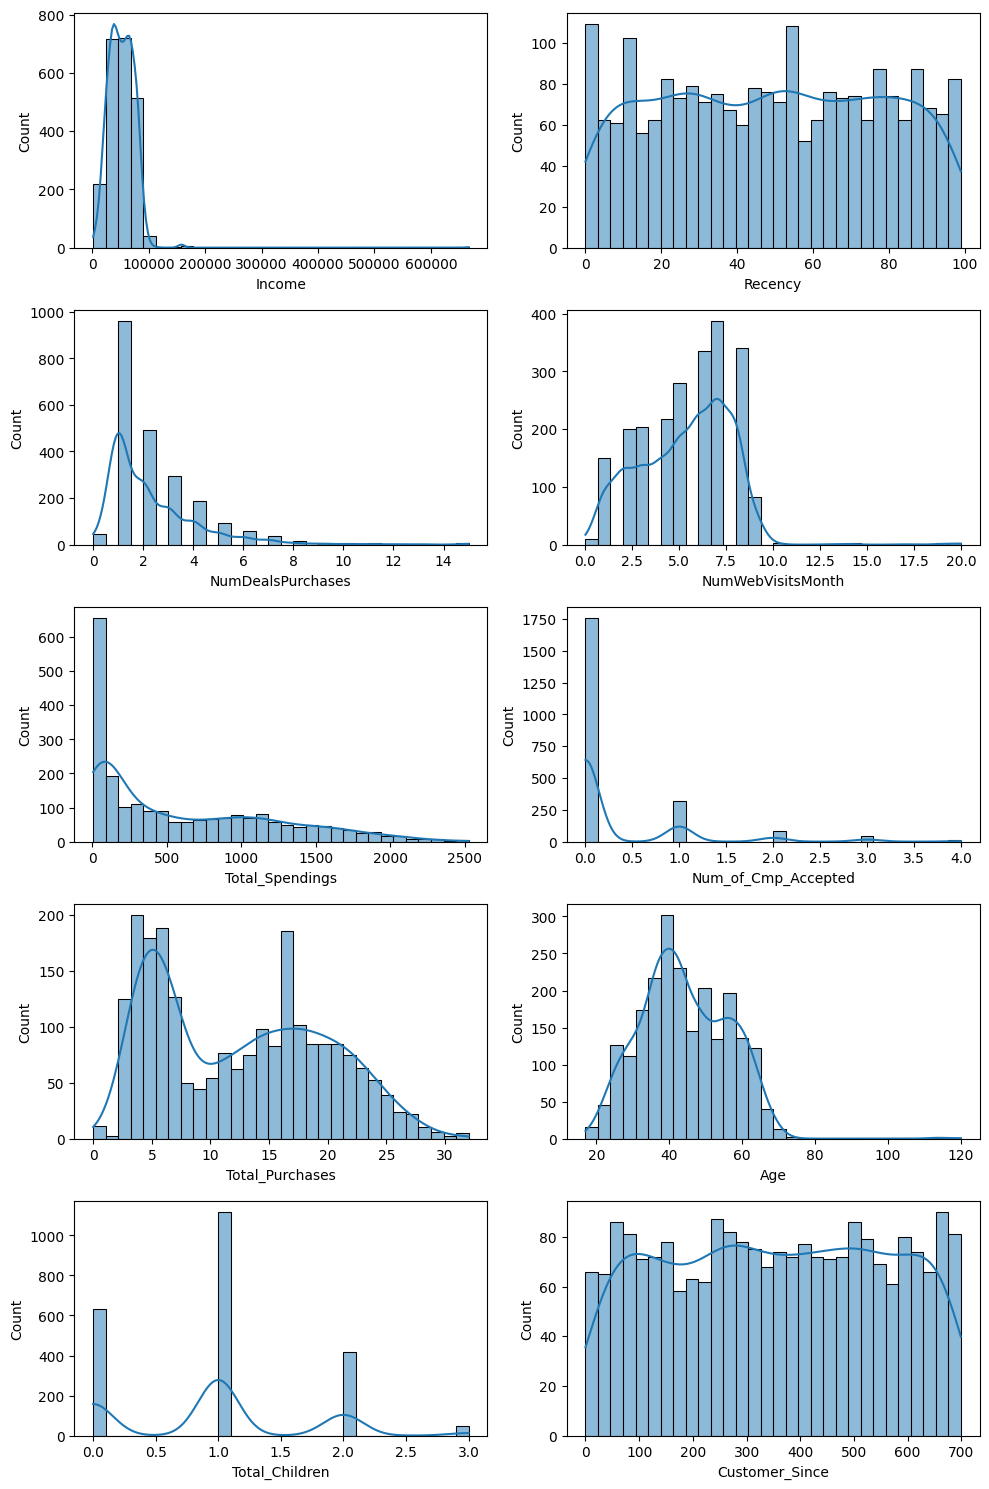

In [28]:
fig,ax=plt.subplots(5,2,figsize=(10,15))
ax=ax.flatten()
for i,col in enumerate(num_cols):
    sns.histplot(x=df[col],ax=ax[i],bins=30,kde=True)
plt.tight_layout()
plt.show()

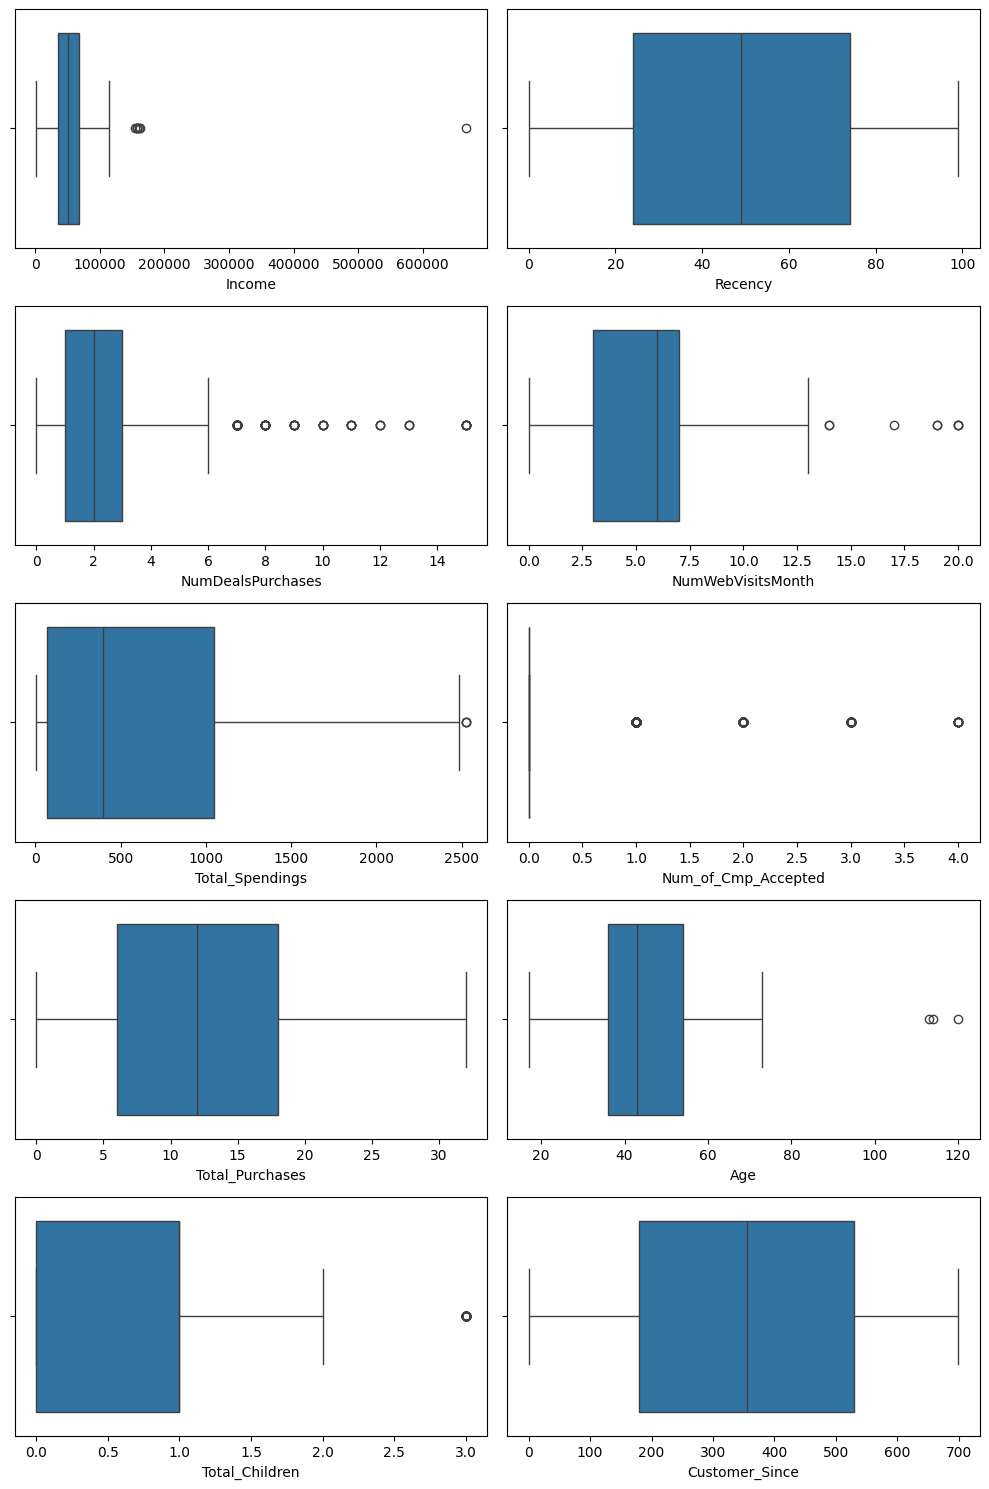

In [29]:
fig,ax=plt.subplots(5,2,figsize=(10,15))
ax=ax.flatten()
for i,col in enumerate(num_cols):
    sns.boxplot(x=df[col],ax=ax[i],vert=False)
plt.tight_layout()
plt.show()

In [30]:
df[df['Income']>100000]

,ID,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebVisitsMonth,Complain,Response,Total_Spendings,Num_of_Cmp_Accepted,Total_Purchases,Age,Total_Children,Customer_Since
124,7215,Graduation,Single,101970.0,69,0,2,0,1,1135,3,27,30,0,474
164,8475,PhD,Married,157243.0,98,15,0,0,0,1608,0,22,40,1,120
203,2798,PhD,Together,102160.0,54,0,4,0,1,1240,3,26,36,0,604
252,10089,Graduation,Divorced,102692.0,5,1,2,0,1,1112,4,28,39,0,450
617,1503,PhD,Together,162397.0,31,0,1,0,0,107,0,1,37,2,391
646,4611,Graduation,Together,105471.0,36,0,3,0,1,1724,2,30,43,0,524
655,5555,Graduation,Divorced,153924.0,81,0,0,0,0,6,0,0,38,0,142
687,1501,PhD,Married,160803.0,21,15,0,0,0,1717,0,29,31,0,694
1300,5336,Master,Together,157733.0,37,0,1,0,0,59,0,2,42,1,390
1653,4931,Graduation,Together,157146.0,13,0,1,0,0,1730,0,28,36,0,426


In [31]:
df=df.drop((df[df['Income']==666666.0]).index)

In [32]:
print(df[df['Income'] == 666666])

Empty DataFrame
Columns: [ID, Education, Marital_Status, Income, Recency, NumDealsPurchases, NumWebVisitsMonth, Complain, Response, Total_Spendings, Num_of_Cmp_Accepted, Total_Purchases, Age, Total_Children, Customer_Since]
Index: []



### Handling Income Outliers

Most income values were within a reasonable range, but one value (`666666`) was much higher than the others. I treated it as an outlier and removed it to avoid affecting the analysis.


In [33]:
df[df['Age']>100]

,ID,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebVisitsMonth,Complain,Response,Total_Spendings,Num_of_Cmp_Accepted,Total_Purchases,Age,Total_Children,Customer_Since
192,7829,2n Cycle,Divorced,36640.0,99,1,5,1,0,65,0,5,113,1,276
239,11004,2n Cycle,Single,60182.0,23,1,4,0,0,22,0,3,120,1,43
339,1150,PhD,Together,83532.0,36,1,1,0,0,1853,1,14,114,0,276


In [34]:
df=df.drop((df[df['Age']>100]).index)

In [35]:
df[df['Age']>100]

,ID,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebVisitsMonth,Complain,Response,Total_Spendings,Num_of_Cmp_Accepted,Total_Purchases,Age,Total_Children,Customer_Since


In [36]:
df['Total_Children'].max()

3

## Categorical Column Analysis

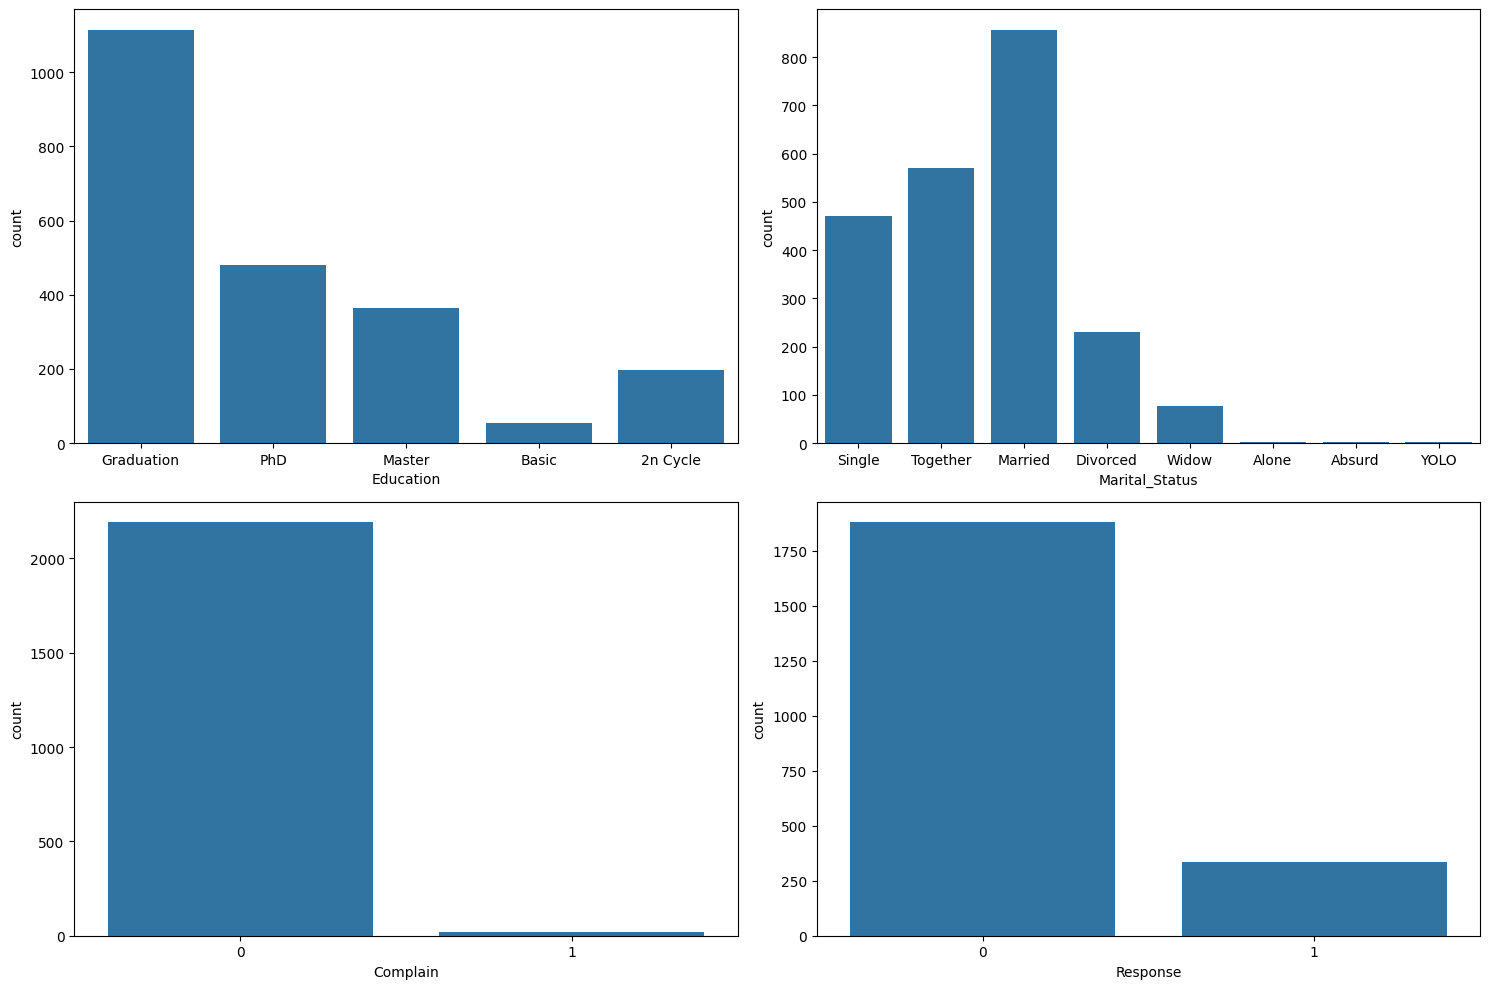

In [37]:
fig,ax=plt.subplots(2,2,figsize=(15,10))
ax=ax.flatten()
for i,col in enumerate(cat_cols):
    sns.countplot(x=df[col],ax=ax[i])
plt.tight_layout()
plt.show()

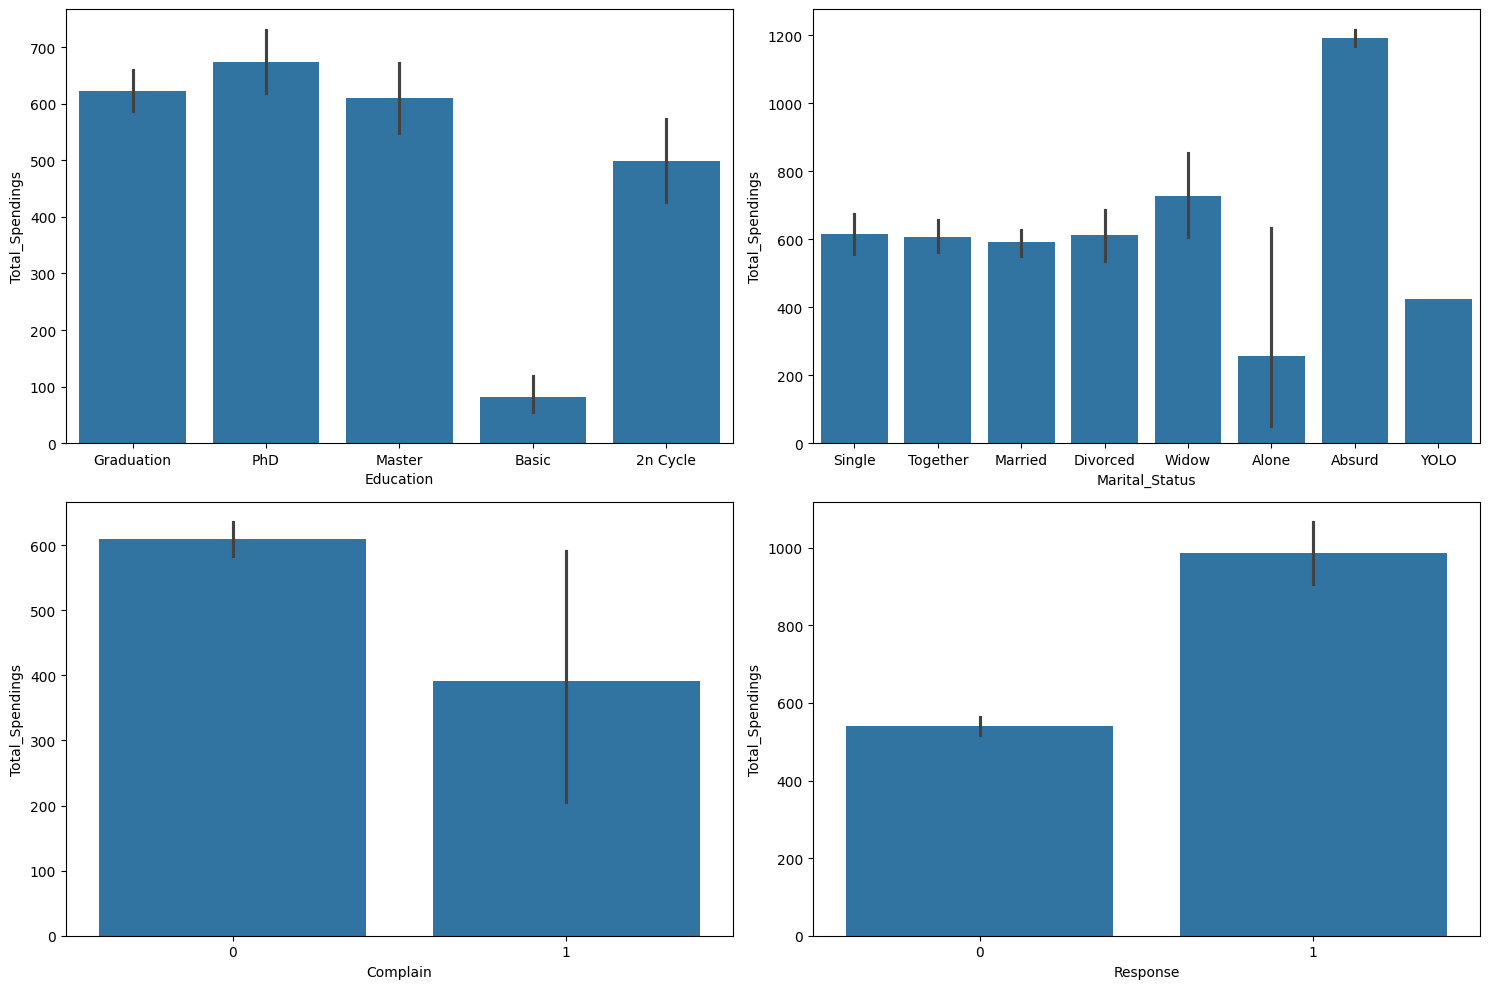

In [38]:
fig,ax=plt.subplots(2,2,figsize=(15,10))
ax=ax.flatten()
for i,col in enumerate(cat_cols):
    sns.barplot(x=df[col],y=df['Total_Spendings'],ax=ax[i])
plt.tight_layout()
plt.show()

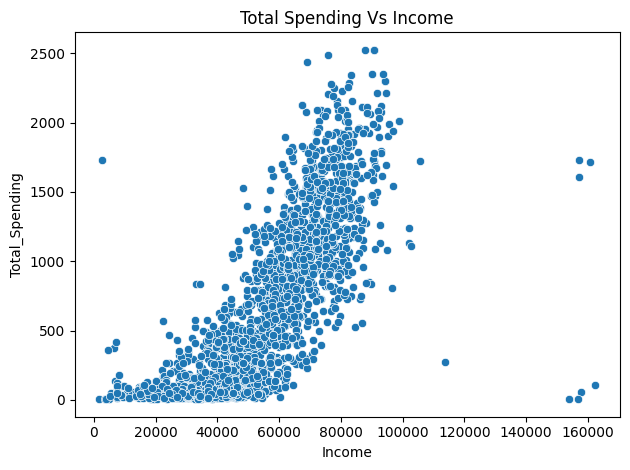

In [39]:
sns.scatterplot(y=df['Total_Spendings'],x=df['Income'])
plt.xlabel("Income")
plt.ylabel("Total_Spending")
plt.title("Total Spending Vs Income")
plt.tight_layout()
plt.show()

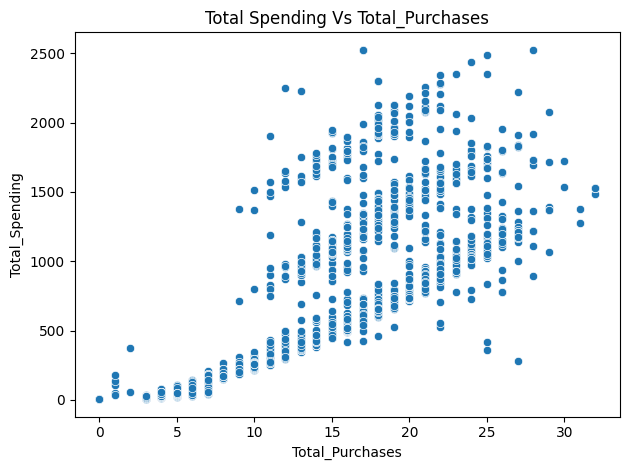

In [40]:
sns.scatterplot(y=df['Total_Spendings'],x=df['Total_Purchases'])
plt.xlabel("Total_Purchases")
plt.ylabel("Total_Spending")
plt.title("Total Spending Vs Total_Purchases")
plt.tight_layout()
plt.show()

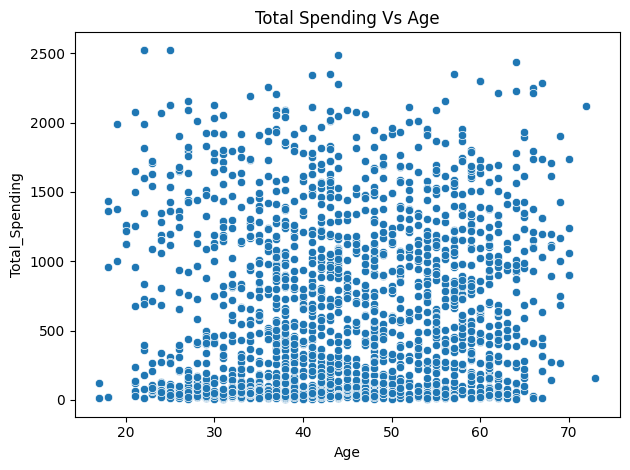

In [41]:
sns.scatterplot(y=df['Total_Spendings'],x=df['Age'])
plt.xlabel("Age")
plt.ylabel("Total_Spending")
plt.title("Total Spending Vs Age")
plt.tight_layout()
plt.show()

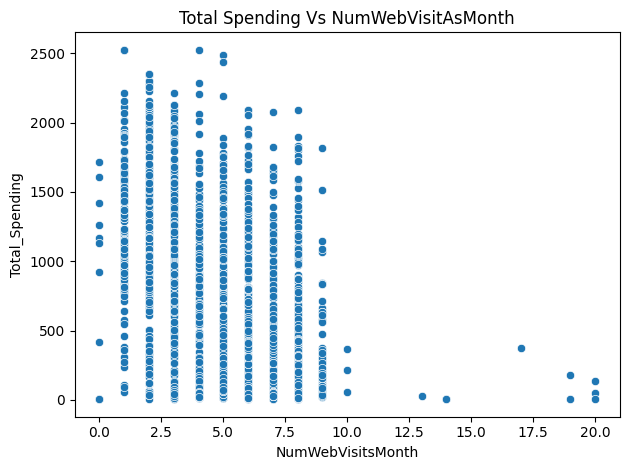

In [42]:
sns.scatterplot(y=df['Total_Spendings'],x=df['NumWebVisitsMonth'])
plt.xlabel("NumWebVisitsMonth")
plt.ylabel("Total_Spending")
plt.title("Total Spending Vs NumWebVisitAsMonth")
plt.tight_layout()
plt.show()

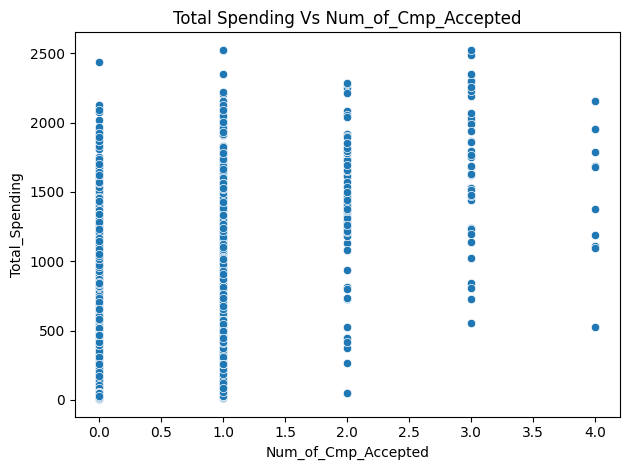

In [43]:
sns.scatterplot(y=df['Total_Spendings'],x=df['Num_of_Cmp_Accepted'])
plt.xlabel("Num_of_Cmp_Accepted")
plt.ylabel("Total_Spending")
plt.title("Total Spending Vs Num_of_Cmp_Accepted")
plt.tight_layout()
plt.show()

## Correlation Analysis

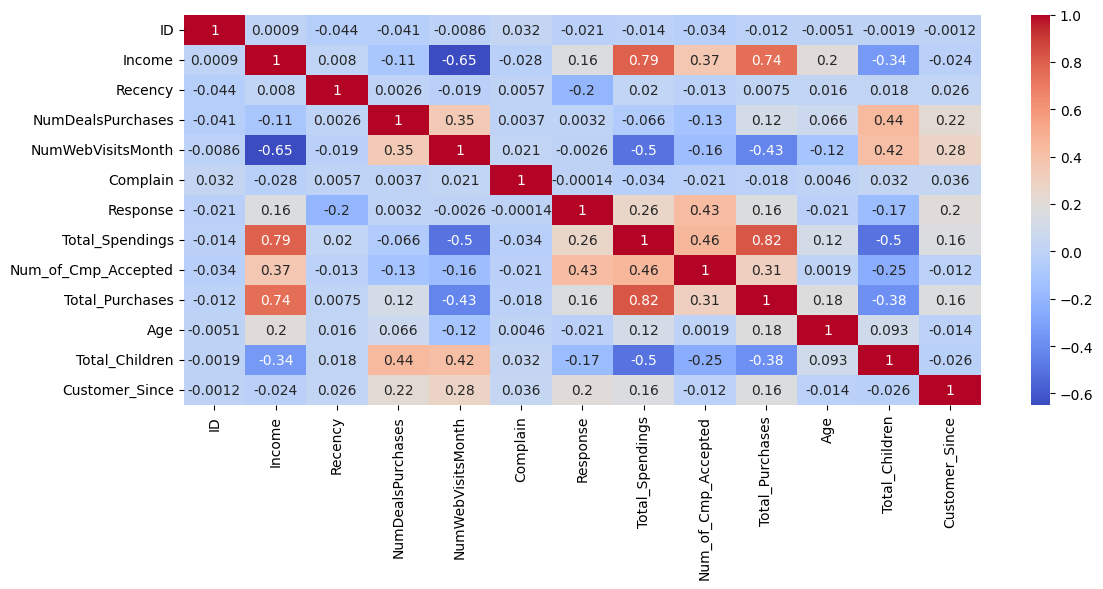

In [44]:
plt.figure(figsize=(12,6))
corr=df.select_dtypes('number').corr()
sns.heatmap(data=corr,cmap='coolwarm',annot=True)
plt.tight_layout()
plt.show()

## Data Preprocessing

In [45]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [46]:
features=['Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Total_Spendings', 'Num_of_Cmp_Accepted',
       'Total_Purchases', 'Total_Children', 'Customer_Since',
      ]

In [47]:
X=df[features].copy()

In [48]:
scaler=StandardScaler()
scaled_data=scaler.fit_transform(X)

In [49]:
encoded_data=pd.get_dummies(df[['Education','Marital_Status']]).astype('int')

In [50]:
encoded_data.isnull().sum()

Education_2n Cycle         0
Education_Basic            0
Education_Graduation       0
Education_Master           0
Education_PhD              0
Marital_Status_Absurd      0
Marital_Status_Alone       0
Marital_Status_Divorced    0
Marital_Status_Married     0
Marital_Status_Single      0
Marital_Status_Together    0
Marital_Status_Widow       0
Marital_Status_YOLO        0
dtype: int64

In [51]:
scaled_df = pd.DataFrame(
    scaled_data,
    columns=features,
    index=df.index
)


In [52]:
new_df=pd.concat([scaled_df,encoded_data],axis=1)

In [53]:
new_df.columns

Index(['Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Total_Spendings', 'Num_of_Cmp_Accepted',
       'Total_Purchases', 'Total_Children', 'Customer_Since',
       'Education_2n Cycle', 'Education_Basic', 'Education_Graduation',
       'Education_Master', 'Education_PhD', 'Marital_Status_Absurd',
       'Marital_Status_Alone', 'Marital_Status_Divorced',
       'Marital_Status_Married', 'Marital_Status_Single',
       'Marital_Status_Together', 'Marital_Status_Widow',
       'Marital_Status_YOLO'],
      dtype='object')

## Within Cluster Sum of Squares (WCSS)

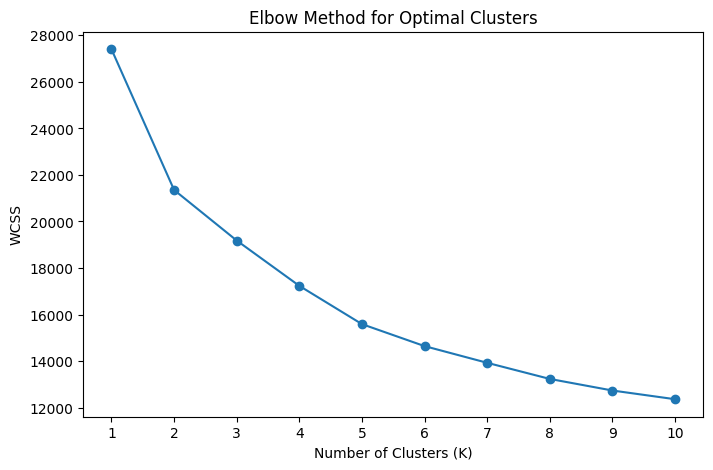

In [54]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(new_df)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.show()


## Silhouette Score

In [55]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
silhouette_scores = {}
for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(new_df)
    score = silhouette_score(new_df, labels)
    silhouette_scores[k] = score
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2248
K = 3, Silhouette Score = 0.2348
K = 4, Silhouette Score = 0.1854
K = 5, Silhouette Score = 0.2009
K = 6, Silhouette Score = 0.2021
K = 7, Silhouette Score = 0.1479
K = 8, Silhouette Score = 0.1358



### Selecting the Number of Clusters

The Elbow Method shows a noticeable decrease in WCSS as the number of clusters increases. I selected **2 clusters** to keep the customer groups simple and easy to understand.


## Model Training

In [56]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(new_df)

print(df['Cluster'].value_counts().sort_index())


Cluster
0    1316
1     896
Name: count, dtype: int64


## Principle Component Analysis

In [57]:
from sklearn.decomposition import PCA

In [58]:
pca = PCA(n_components=2)
pca_data = pca.fit_transform(new_df)
df['PCA1'] = pca_data[:, 0]
df['PCA2'] = pca_data[:, 1]
print(
    "Variance preserved:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Variance preserved: 42.31 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


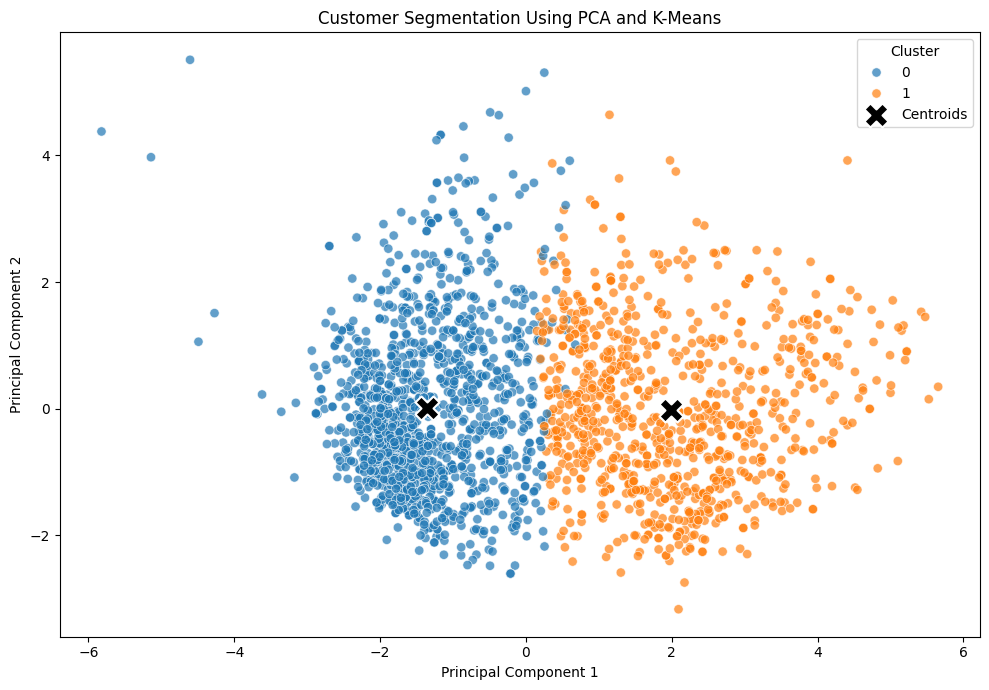

In [59]:
plot_df = pd.DataFrame(
    pca_data,
    columns=['PCA1', 'PCA2'],
    index=new_df.index
)
plot_df['Cluster'] = df['Cluster'].values
centroids_pca = pca.transform(kmeans.cluster_centers_)
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    s=45,
    alpha=0.7
)
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=300,
    c='black',
    edgecolors='white',
    linewidths=1.5,
    label='Centroids',
    zorder=5
)
plt.title('Customer Segmentation Using PCA and K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()


<Axes: xlabel='Cluster'>

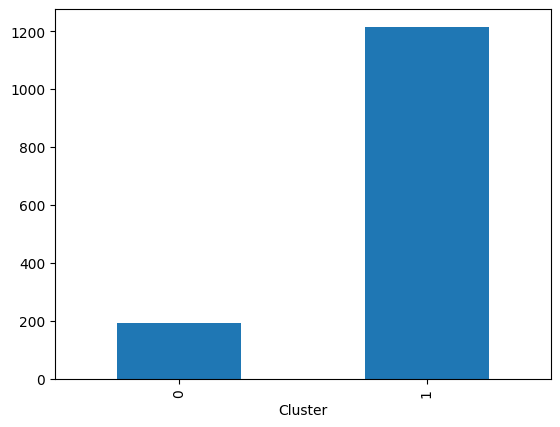

In [60]:
df.groupby('Cluster')['Total_Spendings'].mean().sort_values().plot(kind='bar')

In [61]:
df['Cluster'].value_counts()

Cluster
0    1316
1     896
Name: count, dtype: int64

In [62]:
df.groupby('Cluster')[['Income', 'Total_Spendings', 'Total_Purchases']].mean()

,Income,Total_Spendings,Total_Purchases
Cluster,,,
0,38140.160334,193.233283,7.827508
1,72254.953125,1215.381696,19.527902



## Conclusion

In this project, I used K-Means Clustering to group customers based on their demographic details, spending habits, purchase history, and other features.

I performed data cleaning, feature engineering, Exploratory Data Analysis, and data preprocessing before applying the clustering algorithm.

I also used the Elbow Method and Silhouette Score to study the number of clusters and PCA to visualize the customer groups.

Finally, I compared the average income, total spending, and total purchases of the clusters to understand how the groups differ.

This project helped me gain practical experience in data analysis and unsupervised machine learning using Python and Scikit-learn.
